<div align="center">

Graph Neural Network for Cell Type Classification (seqFISH)

**AI for BME 487**

Created by [Nazreen Pallikkavaliyaveetil](https://scholar.google.co.in/citations?user=RIp232QAAAAJ&hl=en)  
University of Michigan  

[Google Scholar](https://scholar.google.co.in/citations?user=RIp232QAAAAJ&hl=en) • [GitHub](https://github.com/nazreenpm) • [LinkedIn](https://www.linkedin.com/in/nazreenpm/)

</div>


*******

#Cell Type Prediction from seqFISH Data using Graph Convolutional Networks (GCN)

This notebook demonstrates how to perform cell type classification on spatial transcriptomics data using a Graph Convolutional Network (GCN).
The model leverages both gene expression and spatial neighborhood information to predict cell identities within tissue sections.

It includes:

**Data Loading:** Uses the built-in seqFISH mouse cortex dataset from Squidpy/Scanpy, which contains gene expression profiles, spatial coordinates, and annotated cell types.

**Graph Construction:** Builds a spatial neighbor graph based on cell proximity, connecting nearby cells in the tissue.

**Model Training:** Trains a GCN for node (cell) classification using expression features and the spatial graph structure.

**Performance Evaluation:** Computes accuracy and visualizes a normalized confusion matrix to assess classification performance.


#Dataset Overview

**Dataset:** seqFISH Mouse Cortex (from Squidpy)

**Nodes (cells):** Each node represents an individual cell with its gene expression vector.

**Edges:** Constructed based on spatial proximity between cells, representing their physical neighborhood relationships.

**Labels:** Each cell is annotated with a refined reference cell type (e.g., neuron, astrocyte, endothelial cell).

***************

**Install dependencies: Squidpy, Scanpy, PyTorch + PyG, Anndata, Matplotlib**

In [ ]:
!pip install squidpy scanpy torch torch_geometric anndata matplotlib

In [3]:
!pip install squidpy --no-cache-dir

**Import Libraries**

In [4]:
import torch
if torch.cuda.is_available():
    print("GPU is available:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Check runtime settings.")
import squidpy as sq
import scanpy as sc
from torch_geometric.data import Data
import numpy as np
from torch_geometric.nn import GCNConv
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay



A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Users/gopalsrivastava/miniconda/envs/erdos_ds_environment/lib/python3.12/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/Users/gopalsrivastava/miniconda/envs/erdos_ds_environment/lib/python3.12/site-packages/traitlets/config/application.py", line 1082, in launch_instance
    app.start()
  File "/Users/gopalsrivastava/miniconda/envs/erdos_ds_environment/lib/pytho

GPU not available. Check runtime settings.


ImportError: cannot import name 'sentinel' from 'typing_extensions' (/Users/gopalsrivastava/miniconda/envs/erdos_ds_environment/lib/python3.12/site-packages/typing_extensions.py)

**Load seqFISH mouse cortex spatial transcriptomics dataset**

In [ ]:
adata = sq.datasets.seqfish()
print(adata)


**Visualize spatial distribution of cells colored by their mapped cell types**

/usr/local/lib/python3.12/dist-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


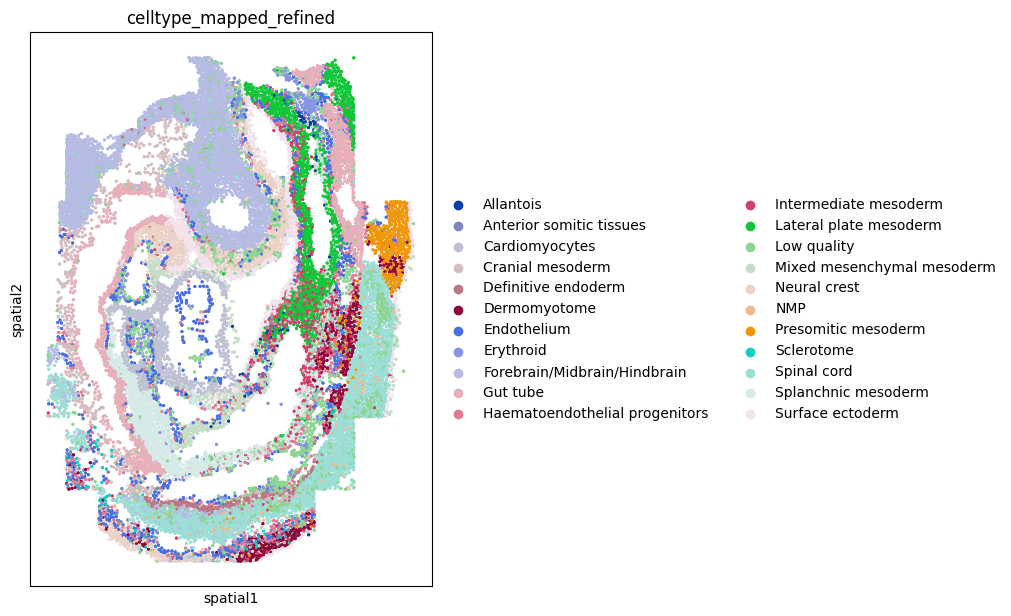

In [ ]:
sq.pl.spatial_scatter(
    adata, color="celltype_mapped_refined", shape=None, figsize=(10, 10)
)



**spatial graph computation and data formatting**


In [ ]:
sq.gr.spatial_neighbors(adata, coord_type="generic", n_neighs=8)


In [ ]:
# Features: expression
X_dense = adata.X.A if hasattr(adata.X, "A") else adata.X.toarray()
x = torch.tensor(X_dense, dtype=torch.float)

# Labels: cell type indices
cell_types = adata.obs["celltype_mapped_refined"].astype("category")
y = torch.tensor(cell_types.cat.codes.values, dtype=torch.long)

# Graph edges
adj = adata.obsp["spatial_connectivities"]
edge_index = torch.tensor(np.vstack(adj.nonzero()), dtype=torch.long)

# Create PyG Data object
data = Data(x=x, edge_index=edge_index, y=y)


**Define the GCN Model**

In [ ]:

class GCN(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super().__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)

    def forward(self, x, edge_index):
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=0.3, training=self.training)
        x = self.conv2(x, edge_index)
        return F.log_softmax(x, dim=1)


**Model Training Loop**

In [ ]:

# Split nodes into training and test sets, define GCN model, and train with supervised node classification
idx_train, idx_test = train_test_split(
    np.arange(data.num_nodes), test_size=0.2, stratify=data.y
)

train_mask = torch.zeros(data.num_nodes, dtype=torch.bool)
test_mask = torch.zeros(data.num_nodes, dtype=torch.bool)
train_mask[idx_train] = True
test_mask[idx_test] = True

data.train_mask = train_mask
data.test_mask = test_mask

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = GCN(data.num_features, 64, len(cell_types.cat.categories)).to(device)
data = data.to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)

for epoch in range(1, 201):
    model.train()
    optimizer.zero_grad()
    out = model(data.x, data.edge_index)
    loss = F.nll_loss(out[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()

    if epoch % 5 == 0:
        model.eval()
        pred = out.argmax(dim=1)
        acc = (pred[data.test_mask] == data.y[data.test_mask]).float().mean()
        print(f"Epoch {epoch}, Loss: {loss.item():.4f}, Test Acc: {acc.item():.4f}")


Epoch 5, Loss: 2.0124, Test Acc: 0.5340
Epoch 10, Loss: 1.3721, Test Acc: 0.6599
Epoch 15, Loss: 1.1716, Test Acc: 0.6838
Epoch 20, Loss: 1.0590, Test Acc: 0.7024
Epoch 25, Loss: 0.9812, Test Acc: 0.7104
Epoch 30, Loss: 0.9417, Test Acc: 0.7183
Epoch 35, Loss: 0.9166, Test Acc: 0.7240
Epoch 40, Loss: 0.8895, Test Acc: 0.7309
Epoch 45, Loss: 0.8689, Test Acc: 0.7240
Epoch 50, Loss: 0.8528, Test Acc: 0.7266
Epoch 55, Loss: 0.8413, Test Acc: 0.7315
Epoch 60, Loss: 0.8250, Test Acc: 0.7327
Epoch 65, Loss: 0.8154, Test Acc: 0.7255
Epoch 70, Loss: 0.8075, Test Acc: 0.7327
Epoch 75, Loss: 0.8016, Test Acc: 0.7361
Epoch 80, Loss: 0.7924, Test Acc: 0.7351
Epoch 85, Loss: 0.7871, Test Acc: 0.7284
Epoch 90, Loss: 0.7810, Test Acc: 0.7299
Epoch 95, Loss: 0.7711, Test Acc: 0.7312
Epoch 100, Loss: 0.7700, Test Acc: 0.7320
Epoch 105, Loss: 0.7629, Test Acc: 0.7333
Epoch 110, Loss: 0.7576, Test Acc: 0.7286
Epoch 115, Loss: 0.7569, Test Acc: 0.7291
Epoch 120, Loss: 0.7524, Test Acc: 0.7322
Epoch 125, L

**Evaluate Model and Plot Confusion Matrix**

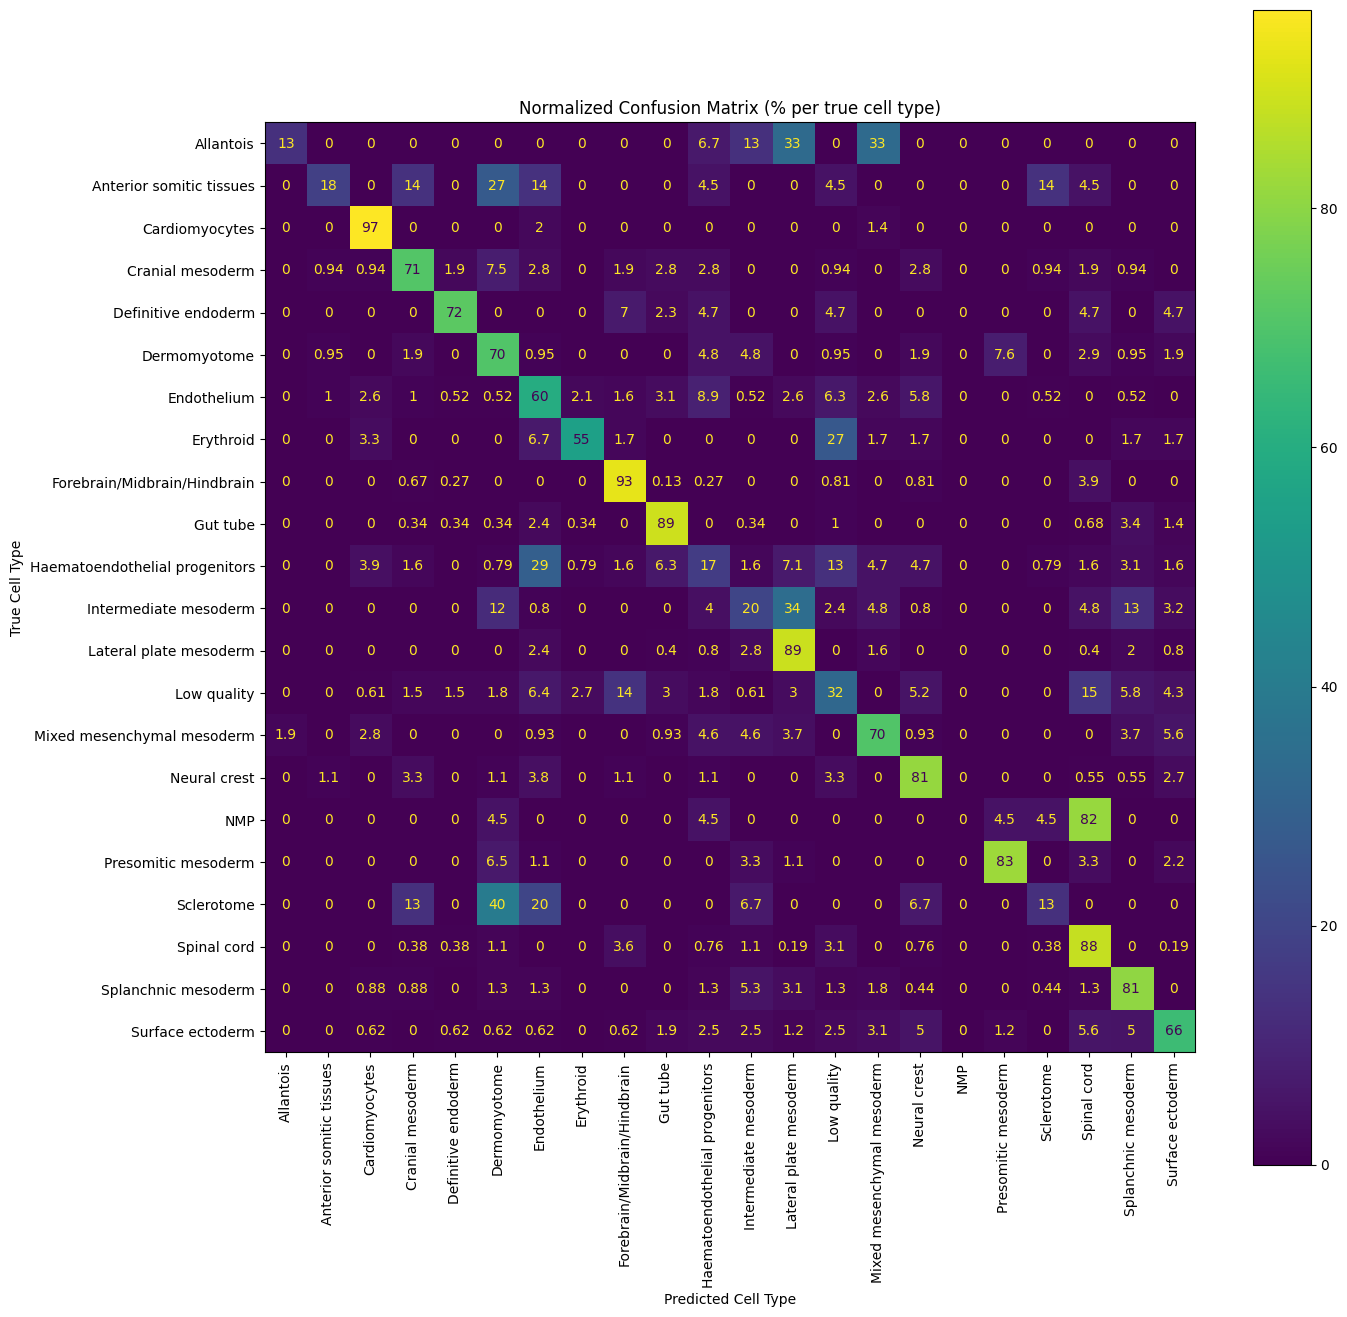

In [ ]:

model.eval()
out = model(data.x, data.edge_index)
pred = out[data.test_mask].argmax(dim=1).cpu().numpy()
y_true = data.y[data.test_mask].cpu().numpy()

# Normalize per true label (row-wise)
cm = confusion_matrix(y_true, pred, normalize='true') * 100  # convert to %

disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=cell_types.cat.categories)

fig, ax = plt.subplots(figsize=(15,15))
disp.plot(ax=ax, cmap='viridis', colorbar=True)
plt.title("Normalized Confusion Matrix (% per true cell type)")
plt.xlabel("Predicted Cell Type")
plt.ylabel("True Cell Type")
plt.xticks(rotation=90)
plt.show()
